# LSTM

In [ ]:
# ================================
# LSTM: run per-store (no scaling leakage), log1p target, report errors in dollars
# Trains one model per store and aggregates MAE/RMSE
# ================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping

# Settings - tune as needed
seq_len = 10
epochs = 30  # change if you want longer training
batch_size = 32

# Helper to compute Thanksgiving (4th Thursday of November)
def thanksgiving_date(year):
    d = pd.Timestamp(year=year, month=11, day=1)
    first_thursday = 1 + ((3 - d.weekday()) % 7)
    return pd.Timestamp(year=year, month=11, day=first_thursday + 21).date()

def mean_absolute_percentage_error(y_true, y_pred): 
    """Calculates MAPE (Mean Absolute Percentage Error)"""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Mask to avoid division by zero
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# Load data
df = pd.read_csv("features.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

# Features to use
# 2. Dynamic Feature Selection
# Columns to exclude (IDs, Targets, and duplicate target representations)
exclude_cols = ['Store', 'Date', 'Weekly_Sales', 'sales_log1p']

# Select all other columns present in the file as features
exog_cols = [c for c in df.columns if c not in exclude_cols]
target = 'Weekly_Sales'

stores = sorted(df['Store'].unique())
results = []

for store_id in stores:
    print(f"\nProcessing store {store_id}")
    store_df = df[df['Store'] == store_id].reset_index(drop=True)
    n = len(store_df)
    if n <= seq_len + 5:
        print(f"Skipping store {store_id}: not enough rows ({n})")
        continue

    raw_X = store_df[exog_cols].values
    raw_y = store_df[[target]].values.flatten()

    # sequences counts and splits per-store
    num_seq = n - seq_len
    train_seq = int(0.7 * num_seq)
    val_seq = int(0.15 * num_seq)
    test_seq = num_seq - train_seq - val_seq
    fit_end = seq_len + train_seq

    # target log transform with safety shift
    min_y = raw_y.min()
    shift = float(-min_y + 1.0) if min_y < 0 else 0.0
    if shift > 0:
        print(f"Store {store_id}: applying shift={shift} to target before log1p")
    raw_y_shifted = raw_y + shift
    raw_y_log = np.log1p(raw_y_shifted)

    # Fit scalers on training portion only (no leakage)
    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()
    scaler_X.fit(raw_X[:fit_end])
    scaler_y.fit(raw_y_log[:fit_end].reshape(-1, 1))

    X_scaled = scaler_X.transform(raw_X)
    y_scaled = scaler_y.transform(raw_y_log.reshape(-1, 1))

    # Create sequences
    def create_sequences(X, y, seq_len=10):
        Xs, ys = [], []
        for i in range(seq_len, len(X)):
            Xs.append(X[i-seq_len:i])
            ys.append(y[i])
        return np.array(Xs), np.array(ys)

    X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

    X_train = X_seq[:train_seq]
    y_train = y_seq[:train_seq]
    X_val = X_seq[train_seq:train_seq+val_seq]
    y_val = y_seq[train_seq:train_seq+val_seq]
    X_test = X_seq[train_seq+val_seq:]
    y_test = y_seq[train_seq+val_seq:]

    print(f"Store {store_id}: total sequences={num_seq}, train={len(X_train)}, val={len(X_val)}, test={len(X_test)}")

    if len(X_train) == 0 or len(X_test) == 0:
        print(f"Skipping store {store_id}: empty train/test after split")
        continue

    n_features = X_train.shape[2]

    # Build model
    tf.keras.backend.clear_session()
    model = Sequential()
    model.add(LSTM(128, return_sequences=True, input_shape=(seq_len, n_features)))
    model.add(BatchNormalization())
    model.add(Dropout(0.3))
    model.add(LSTM(64))
    model.add(BatchNormalization())
    model.add(Dropout(0.2))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1))
    model.compile(optimizer=Adam(learning_rate=0.001), loss=tf.keras.losses.Huber())

    # Callbacks and checkpoint
    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ]

    # Train
    history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), callbacks=callbacks, verbose=0)
    # Predict and invert transforms back to dollars
    y_pred_scaled = model.predict(X_test)
    y_pred_log = scaler_y.inverse_transform(y_pred_scaled)
    y_pred_orig = np.expm1(y_pred_log).flatten() - shift

    y_test_log = scaler_y.inverse_transform(y_test)
    y_test_orig = np.expm1(y_test_log).flatten() - shift

    mae = mean_absolute_error(y_test_orig, y_pred_orig)
    rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))
    mape = mean_absolute_percentage_error(y_test_orig, y_pred_orig)
    print(f"Store {store_id} - MAE: ${mae:.2f}, RMSE: ${rmse:.2f} , MAPE: {mape:.2f}%")

    results.append({'store': store_id, 'mae': mae, 'rmse': rmse, 'mape': mape, 'n_test': len(y_test_orig), 'forecast': y_pred_orig.tolist(), 'real': y_test_orig.tolist()})

# Aggregate results
if len(results) == 0:
    raise RuntimeError('No stores processed')




Processing store 1
Store 1: total sequences=133, train=93, val=19, test=21


c:\Users\arpit\anaconda3\envs\sales_forecasting\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
Store 1 - MAE: $210795.44, RMSE: $239025.46 , MAPE: 13.16%

Processing store 2
Store 2: total sequences=133, train=93, val=19, test=21
Store 1 - MAE: $210795.44, RMSE: $239025.46 , MAPE: 13.16%

Processing store 2
Store 2: total sequences=133, train=93, val=19, test=21


c:\Users\arpit\anaconda3\envs\sales_forecasting\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step
Store 2 - MAE: $316313.45, RMSE: $326812.24 , MAPE: 16.66%

Processing store 3
Store 3: total sequences=133, train=93, val=19, test=21
Store 2 - MAE: $316313.45, RMSE: $326812.24 , MAPE: 16.66%

Processing store 3
Store 3: total sequences=133, train=93, val=19, test=21


...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step
Store 43 - MAE: $62597.72, RMSE: $67051.75 , MAPE: 10.01%

Processing store 44
Store 44: total sequences=133, train=93, val=19, test=21
Store 43 - MAE: $62597.72, RMSE: $67051.75 , MAPE: 10.01%

Processing store 44
Store 44: total sequences=133, train=93, val=19, test=21


c:\Users\arpit\anaconda3\envs\sales_forecasting\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step
Store 44 - MAE: $92647.93, RMSE: $93330.77 , MAPE: 27.25%

Processing store 45
Store 45: total sequences=133, train=93, val=19, test=21
Store 44 - MAE: $92647.93, RMSE: $93330.77 , MAPE: 27.25%

Processing store 45
Store 45: total sequences=133, train=93, val=19, test=21


c:\Users\arpit\anaconda3\envs\sales_forecasting\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step
Store 45 - MAE: $38234.40, RMSE: $50632.75 , MAPE: 4.92%
Store 45 - MAE: $38234.40, RMSE: $50632.75 , MAPE: 4.92%


In [10]:
res_df = pd.DataFrame(results)

# Print stores sorted by MAPE (ascending) — one concise line per store with MAPE, MAE, RMSE
sorted_by_mape = res_df.sort_values('mape').reset_index(drop=True)
print("\nStores sorted by MAPE (ascending):")
for _, r in sorted_by_mape.iterrows():
    print(f"Store {int(r['store']):3d} | MAPE={r['mape']:6.2f}% | MAE=${r['mae']:7.2f} | RMSE=${r['rmse']:7.2f}")

# Brief aggregates (simple + weighted)
simple_mae = res_df['mae'].mean()
simple_rmse = res_df['rmse'].mean()
simple_mape = res_df['mape'].mean()

sorted_by_mape.to_csv("lstm_store_results.csv", index=False)

print('\nSummary:')
print(f"Stores evaluated: {len(res_df)}")
print(f"Simple averages -> MAE=${simple_mae:.2f}, RMSE=${simple_rmse:.2f}, MAPE={simple_mape:.2f}%")
# print(f"Weighted averages -> MAE=${weighted_mae:.2f}, RMSE=${weighted_rmse:.2f}, MAPE={weighted_mape:.2f}%")


Stores sorted by MAPE (ascending):
Store  27 | MAPE=  4.25% | MAE=$74517.46 | RMSE=$101832.68
Store  45 | MAPE=  4.92% | MAE=$38234.40 | RMSE=$50632.75
Store  40 | MAPE=  6.45% | MAE=$67736.99 | RMSE=$92340.90
Store  11 | MAPE=  6.55% | MAE=$89395.76 | RMSE=$105877.51
Store  14 | MAPE=  6.94% | MAE=$118755.06 | RMSE=$146675.29
Store  39 | MAPE=  6.99% | MAE=$113187.59 | RMSE=$135342.99
Store  17 | MAPE=  7.00% | MAE=$72529.65 | RMSE=$111426.00
Store  28 | MAPE=  7.29% | MAE=$98945.77 | RMSE=$146199.36
Store  36 | MAPE=  7.40% | MAE=$22808.76 | RMSE=$28167.88
Store   8 | MAPE=  7.85% | MAE=$72314.13 | RMSE=$81748.80
Store  20 | MAPE=  8.72% | MAE=$186318.58 | RMSE=$212882.26
Store  21 | MAPE=  8.78% | MAE=$63252.60 | RMSE=$77503.65
Store  30 | MAPE=  8.83% | MAE=$38379.13 | RMSE=$40436.95
Store  37 | MAPE=  8.96% | MAE=$47060.71 | RMSE=$50480.71
Store  43 | MAPE= 10.01% | MAE=$62597.72 | RMSE=$67051.75
Store  15 | MAPE= 10.28% | MAE=$63199.50 | RMSE=$76214.90
Store  10 | MAPE= 10.37% |

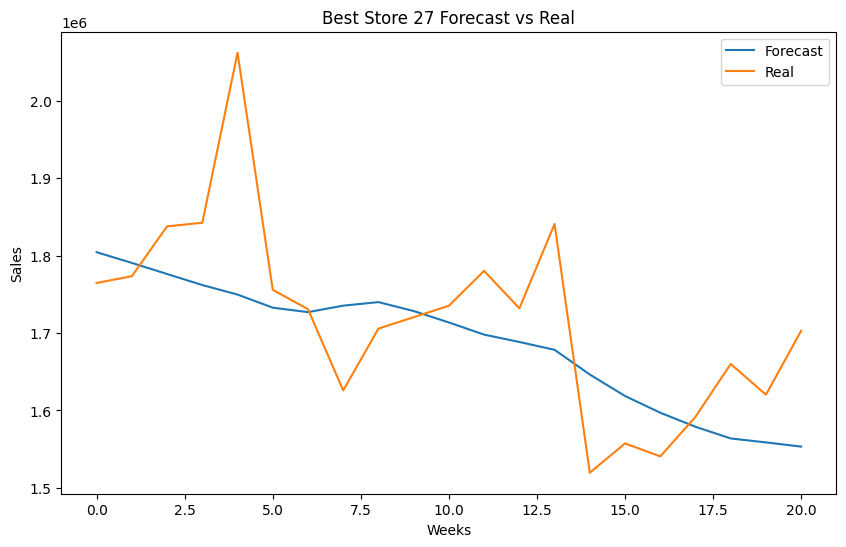

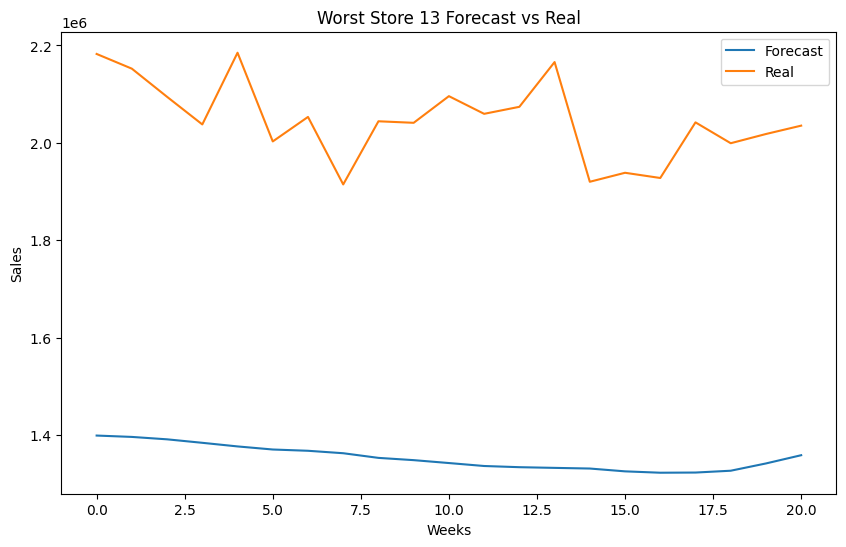

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(sorted_by_mape.iloc[0]['forecast'], label='Forecast')
plt.plot(sorted_by_mape.iloc[0]['real'], label='Real')
plt.title(f'Best Store {int(sorted_by_mape.iloc[0]["store"])} Forecast vs Real')
plt.xlabel('Weeks')
plt.ylabel('Sales')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sorted_by_mape.iloc[-1]['forecast'], label='Forecast')
plt.plot(sorted_by_mape.iloc[-1]['real'], label='Real')
plt.title(f'Worst Store {int(sorted_by_mape.iloc[-1]["store"])} Forecast vs Real')
plt.xlabel('Weeks')
plt.ylabel('Sales')
plt.legend()
plt.show()